# Part 4-1. 매출 예측: 중첩 Walk-Forward 검증

**목적:** Part 4의 매출 예측(단일 분할, 하루 전 예측, LightGBM 하나)을 **Part 3-1과 같은 검증 프로토콜**로 다시 평가한다. 바깥 평가 구간 3개(2017-03-17 ~ 08-31, 168일), 구간마다 그 이전 데이터만으로 EDA 그룹 선택, 튜닝, 모델 선택을 처음부터 수행하고, 9개 모델을 비교한다.

**타깃:** 호텔별 일별 매출 `revenue` = 취소되지 않은 예약의 `adr × 숙박일수`, 투숙 시작일 기준, `0 < adr < 1000`만 사용. **예측 시점은 7일 전(H7).**

**Part 3-1과 달라진 점**
- **매출 전용 피처:** `otb_rev_N`(투숙 N일 전에 이미 잡힌 예약의 예상 매출), `exp_rev_N`(취소 확률로 보정한 기대 순매출 = Σ(1 − 취소확률) × adr × 숙박일수)를 추가. `otb_rev_*`는 베이스라인에 포함, `exp_rev_*`는 `cancel` 그룹에 포함
- SARIMAX의 외생변수는 `otb_rev_7`, `exp_rev_7`
- 취소 확률은 Part 3-1과 같은 expanding window 결과(`cache_nested/p_cancel.npy`)를 재사용 (예약 이후 변수 제외)
- **선택 절차 B(상위 3개 평균)의 K=3은 이 노트북의 결과를 보기 전에 고정**했다. 다만 수요와 매출은 매우 비슷한 신호라서 Part 3-1의 Resort 결과를 본 뒤 정한 규칙이며, 완전히 독립된 검증은 아니다.

검증 설계, 피처 그룹, 모델 목록은 Part 3-1과 동일하다 (EDA 그룹: segment, biased, history, leadtime, price, size, attrs, cancel, cancel_lag, calendar, trend).

> **실행 방식:** `OUTER_RUN` 환경변수로 계산할 바깥 구간을 지정하고, 중간 결과는 `cache_rev/`에 저장한다.

In [1]:
import os, time, pickle, warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import lightgbm as lgb
import holidays
import matplotlib.pyplot as plt
from itertools import product
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('cache_nested', exist_ok=True); os.makedirs('cache_rev', exist_ok=True)
OUTER_RUN = [int(x) for x in os.environ.get('OUTER_RUN', '').split(',') if x.strip() != '']
print("이번 실행에서 계산할 바깥 구간:", OUTER_RUN or '(없음, 저장된 결과만 집계)')

df = pd.read_csv('hotel_bookings.csv')
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
df['nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['revenue'] = df['adr'] * df['nights']
df['valid_price'] = (df['adr'] > 0) & (df['adr'] < 1000)
print(df.shape)

이번 실행에서 계산할 바깥 구간: (없음, 저장된 결과만 집계)


(119390, 36)


## 1. 취소 확률: Expanding Window (과거 데이터만 사용)

- 구간 k의 취소 확률 = 구간 0~k-1 예약만으로 학습한 모델의 예측. 처음 3개 구간(약 135일)은 확률을 만들지 않고 **매출 데이터에서도 제외**
- 예측 시점에 알 수 없는 변수(`booking_changes`, `total_of_special_requests`, `days_in_waiting_list`)와 `arrival_date_year`는 제외, agent 타깃 인코딩은 학습 구간 안에서만 계산
- 이 확률은 한 번만 계산해 `cache_nested/p_cancel.npy`에 저장 (바깥 구간과 무관하게 항상 "그 시점 이전 데이터만" 사용하므로 재사용 가능)

In [2]:
RAW_COLS = ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month',
            'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
            'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations',
            'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type', 'adr', 'agent']
CAT_COLS = ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type',
            'deposit_type', 'customer_type', 'arrival_date_month']
raw = df[RAW_COLS].copy()
raw['children'] = raw['children'].fillna(0); raw['country'] = raw['country'].fillna('Unknown'); raw['agent'] = raw['agent'].fillna(0)
y_all = df['is_canceled'].values
CANCEL_PARAMS = {'objective': 'binary', 'learning_rate': 0.05, 'num_leaves': 31, 'feature_fraction': 0.8,
                 'bagging_fraction': 0.8, 'bagging_freq': 5, 'verbose': -1, 'seed': 42}

def cancel_fit_predict(tr_idx, ap_idx, rounds=300):
    tr, ap = raw.iloc[tr_idx].copy(), raw.iloc[ap_idx].copy()
    ytr = y_all[tr_idx]; gm = ytr.mean()
    agg = pd.DataFrame({'a': tr['agent'].values, 'y': ytr}).groupby('a')['y'].agg(['mean', 'count'])
    sm = (agg['mean'] * agg['count'] + gm * 100) / (agg['count'] + 100)
    for d in (tr, ap):
        d['agent_te'] = d['agent'].map(sm).fillna(gm); d.drop(columns=['agent'], inplace=True)
    top = tr['country'].value_counts().head(20).index
    for d in (tr, ap):
        d['country'] = d['country'].where(d['country'].isin(top), 'Other')
    for c in CAT_COLS:
        cats = pd.Categorical(tr[c]).categories
        tr[c] = pd.Categorical(tr[c], categories=cats); ap[c] = pd.Categorical(ap[c], categories=cats)
    return lgb.train(CANCEL_PARAMS, lgb.Dataset(tr, label=ytr), num_boost_round=rounds).predict(ap)

CHUNK_DAYS, MIN_CHUNKS = 45, 3
t0 = df['arrival_date'].min()
chunk = ((df['arrival_date'] - t0).dt.days // CHUNK_DAYS).values
P_START = t0 + pd.Timedelta(days=MIN_CHUNKS * CHUNK_DAYS)
if os.path.exists('cache_nested/p_cancel.npy'):
    p = np.load('cache_nested/p_cancel.npy')
else:
    p = np.full(len(df), np.nan)
    for k in range(MIN_CHUNKS, chunk.max() + 1):
        tr_idx, ap_idx = np.where(chunk < k)[0], np.where(chunk == k)[0]
        p[ap_idx] = cancel_fit_predict(tr_idx, ap_idx)
    np.save('cache_nested/p_cancel.npy', p)
df['p_cancel'] = p
ok = ~np.isnan(p)
print(f"취소 모델 AUC (과거만 학습, {ok.sum():,}건): {roc_auc_score(y_all[ok], p[ok]):.4f}  | 확률 사용 가능 시작일 {P_START.date()}")

취소 모델 AUC (과거만 학습, 101,786건): 0.8585  | 확률 사용 가능 시작일 2015-11-13


## 2. 일별 데이터와 피처 구성 (H7)

모든 피처는 **투숙 7일 전(예측 시점)에 알 수 있는 값**: lag/rolling은 `shift(8)`, OTB·구성 피처는 `lead_time ≥ 7` 예약만, 최근 취소율은 8일 전까지 확정된 값, 공휴일은 미리 알 수 있는 정보.

In [3]:
OTB_DAYS = [7, 14, 30, 60, 90]
b = df.copy()
b['is_groups'] = (b['market_segment'] == 'Groups').astype(int)
b['is_online'] = (b['market_segment'] == 'Online TA').astype(int)
b['is_offline'] = (b['market_segment'] == 'Offline TA/TO').astype(int)
b['is_direct'] = (b['market_segment'] == 'Direct').astype(int)
b['is_corp'] = (b['market_segment'] == 'Corporate').astype(int)
b['is_nonref'] = (b['deposit_type'] == 'Non Refund').astype(int)
b['is_prt'] = (b['country'] == 'PRT').astype(int)
b['is_agent1'] = (b['agent'] == 1.0).astype(int)
b['has_prevcancel'] = (b['previous_cancellations'] > 0).astype(int)
b['guests'] = b['adults'] + b['children'].fillna(0) + b['babies']
b['cust_transient'] = (b['customer_type'] == 'Transient').astype(int)
b['cust_party'] = (b['customer_type'] == 'Transient-Party').astype(int)
b['cust_contract'] = (b['customer_type'] == 'Contract').astype(int)
b['cust_group'] = (b['customer_type'] == 'Group').astype(int)
b['has_kids'] = ((b['children'].fillna(0) > 0) | (b['babies'] > 0)).astype(int)
b['meal_bb'] = (b['meal'] == 'BB').astype(int)
b['meal_hbfb'] = b['meal'].isin(['HB', 'FB']).astype(int)
SHARE = {
    'segment': {'is_groups': 'groups_sh', 'is_online': 'online_sh', 'is_offline': 'offline_sh', 'is_direct': 'direct_sh', 'is_corp': 'corp_sh'},
    'biased': {'is_nonref': 'nonref_sh', 'is_prt': 'prt_sh', 'is_agent1': 'agent1_sh'},
    'history': {'has_prevcancel': 'prevcancel_sh', 'is_repeated_guest': 'repeat_sh'},
    'attrs': {'cust_transient': 'cust_transient_sh', 'cust_party': 'cust_party_sh', 'cust_contract': 'cust_contract_sh',
              'cust_group': 'cust_group_sh', 'has_kids': 'kids_sh', 'meal_bb': 'meal_bb_sh', 'meal_hbfb': 'meal_hbfb_sh'},
}
YEARS = [2015, 2016, 2017]
pt_h = sorted(pd.to_datetime(list(holidays.Portugal(years=YEARS).keys())))
foreign = [set(pd.to_datetime(list(holidays.country_holidays(c, years=YEARS).keys()))) for c in ['GB', 'FR', 'DE', 'ES', 'IE']]
pt_set = set(pt_h)

def calendar_feats(dates):
    dates = pd.to_datetime(pd.Series(dates).values); nxt, prv = [], []
    for d in dates:
        later = [(h - d).days for h in pt_h if h >= d]; earlier = [(d - h).days for h in pt_h if h <= d]
        nxt.append(min(later[0] if later else 14, 14)); prv.append(min(earlier[-1] if earlier else 14, 14))
    return pd.DataFrame({'is_holiday': [int(d in pt_set) for d in dates], 'days_to_next_hol': nxt, 'days_since_hol': prv,
                         'n_foreign_hol': [sum(d in s for s in foreign) for d in dates],
                         'weekofyear': pd.Series(dates).dt.isocalendar().week.astype(int).values})

def make_daily(hotel_name):
    h = df[df['hotel'] == hotel_name]
    cr = h.groupby('arrival_date')['is_canceled'].mean().rename('cancel_rate')
    rv = h[(h['is_canceled'] == 0) & h['valid_price']].groupby('arrival_date')['revenue'].sum().rename('revenue')
    daily = pd.concat([rv, cr], axis=1).reset_index(); daily['revenue'] = daily['revenue'].fillna(0)
    return daily[daily['arrival_date'] >= '2015-08-01'].sort_values('arrival_date').reset_index(drop=True)

def build_frame(hotel_name):
    d = make_daily(hotel_name); y = d['revenue']
    d['dow'] = d['arrival_date'].dt.dayofweek; d['month'] = d['arrival_date'].dt.month
    d['is_weekend'] = (d['dow'] >= 5).astype(int)
    d['lag_8'], d['lag_14'] = y.shift(8), y.shift(14)
    d['roll7_h7'], d['roll14_h7'] = y.shift(8).rolling(7).mean(), y.shift(8).rolling(14).mean()
    d['level_28'], d['level_56'] = y.shift(8).rolling(28).mean(), y.shift(8).rolling(56, min_periods=28).mean()
    d['cancel_rate_7'], d['cancel_rate_28'] = d['cancel_rate'].shift(8).rolling(7).mean(), d['cancel_rate'].shift(8).rolling(28).mean()
    h = b[b['hotel'] == hotel_name]
    for n in OTB_DAYS:
        d[f'otb_{n}'] = d['arrival_date'].map(h[h['lead_time'] >= n].groupby('arrival_date').size()).fillna(0)
    d['otb_pace'] = d['otb_7'] - d['otb_30']
    hv = h[h['valid_price']]
    for n in OTB_DAYS:
        sub = hv[hv['lead_time'] >= n]
        d[f'otb_rev_{n}'] = d['arrival_date'].map(sub.groupby('arrival_date')['revenue'].sum()).fillna(0)
        d[f'exp_rev_{n}'] = d['arrival_date'].map((sub['revenue'] * (1 - sub['p_cancel'])).groupby(sub['arrival_date']).sum()).fillna(0)
    d['otb_rev_pace'] = d['otb_rev_7'] - d['otb_rev_30']
    s7 = h[h['lead_time'] >= 7]; g = s7.groupby('arrival_date')
    parts = [g[list(cols)].mean().rename(columns=cols) for cols in SHARE.values()]
    parts.append(pd.DataFrame({'lead_mean_7': g['lead_time'].mean()}))
    parts.append(pd.DataFrame({'adr_mean_7': s7[s7['valid_price']].groupby('arrival_date')['adr'].mean()}))
    parts.append(pd.DataFrame({'nights_mean_7': g['nights'].mean(), 'guests_mean_7': g['guests'].mean()}))
    risk = pd.DataFrame({'cancel_prob_7': g['p_cancel'].mean(), 'exp_net_7': g.size() - g['p_cancel'].sum()})
    for n in [14, 30]:
        sn = h[h['lead_time'] >= n].groupby('arrival_date'); risk[f'exp_net_{n}'] = sn.size() - sn['p_cancel'].sum()
    parts.append(risk)
    for part in parts:
        for c in part.columns:
            d[c] = d['arrival_date'].map(part[c])
    for c in ['exp_net_7', 'exp_net_14', 'exp_net_30']:
        d[c] = d[c].fillna(0)
    d = pd.concat([d, calendar_feats(d['arrival_date'])], axis=1)
    d = d[d['arrival_date'] >= P_START]
    return d.dropna(subset=['lag_14', 'roll14_h7', 'lag_8', 'level_28', 'cancel_rate_28']).reset_index(drop=True)

frames = {'City': build_frame('City Hotel'), 'Resort': build_frame('Resort Hotel')}
HOTELS = {'City': 'City Hotel', 'Resort': 'Resort Hotel'}
for k, f in frames.items():
    print(k, f.shape, f['arrival_date'].min().date(), '~', f['arrival_date'].max().date())

BASE = ['dow', 'month', 'is_weekend', 'lag_8', 'lag_14', 'roll7_h7', 'roll14_h7'] + [f'otb_{n}' for n in OTB_DAYS] + ['otb_pace'] + [f'otb_rev_{n}' for n in OTB_DAYS] + ['otb_rev_pace']
GROUPS = {
    'segment': list(SHARE['segment'].values()), 'biased': list(SHARE['biased'].values()), 'history': list(SHARE['history'].values()),
    'leadtime': ['lead_mean_7'], 'price': ['adr_mean_7'], 'size': ['nights_mean_7', 'guests_mean_7'], 'attrs': list(SHARE['attrs'].values()),
    'cancel': ['cancel_prob_7', 'exp_net_7', 'exp_net_14', 'exp_net_30', 'exp_rev_7', 'exp_rev_14', 'exp_rev_30'], 'cancel_lag': ['cancel_rate_7', 'cancel_rate_28'],
    'calendar': ['is_holiday', 'days_to_next_hol', 'days_since_hol', 'n_foreign_hol', 'weekofyear'], 'trend': ['level_28', 'level_56'],
}

City (658, 61) 2015-11-13 ~ 2017-08-31
Resort (658, 61) 2015-11-13 ~ 2017-08-31


## 3. 중첩 구간 정의

- 바깥 평가 구간: 데이터 끝에서 거꾸로 56일씩 3개 (`outer 0, 1, 2`), 배포용 `outer 3`은 평가 없이 전체 DEV로 선택만 수행
- 각 바깥 구간 j의 DEV = 그 평가 구간 **이전 데이터 전부**
- DEV 안의 inner walk-forward: 56일 테스트 구간 4개 (각각 그 이전으로 학습, 직전 56일은 early stopping용)

In [4]:
TEST_LEN, VAL_LEN, N_INNER = 56, 56, 4
N = len(frames['City'])
OUTER_TS = {0: N - 3 * TEST_LEN, 1: N - 2 * TEST_LEN, 2: N - TEST_LEN, 3: N}      # 평가 구간 시작 인덱스 (3은 배포용)
for k, ts in OUTER_TS.items():
    f = frames['City']
    dev_end = f['arrival_date'].iloc[ts - 1].date()
    ev = f"{f['arrival_date'].iloc[ts].date()} ~ {f['arrival_date'].iloc[min(ts + TEST_LEN, N) - 1].date()}" if k < 3 else '(없음, 배포용)'
    print(f"outer {k}: DEV {ts}일 (~{dev_end}) | 평가 구간 {ev}")

def inner_folds(ts):
    return [(ts - TEST_LEN * (N_INNER - f) - VAL_LEN, ts - TEST_LEN * (N_INNER - f), ts - TEST_LEN * (N_INNER - f) + TEST_LEN) for f in range(N_INNER)]

def mape(y, p): return float(np.mean(np.abs(y - p) / np.maximum(y, 1)))
def metrics(y, p): return {'MAPE': mape(y, p), 'MAE': float(np.mean(np.abs(y - p))), 'WAPE': float(np.abs(y - p).sum() / y.sum()), '편향': float(np.mean(p - y))}
def to_target(d, mode): return d['revenue'] / d['level_28'] if mode == 'ratio' else d['revenue']
def from_target(pred, d, mode): return pred * d['level_28'].values if mode == 'ratio' else pred

def run_cv(d, fp, folds):
    ys, ps = [], []
    for tr_end, va_end, te_end in folds:
        tr, va, te = d.iloc[:tr_end], d.iloc[tr_end:va_end], d.iloc[va_end:te_end]
        ps.append(np.asarray(fp(tr, va, te), dtype=float)); ys.append(te['revenue'].values)
    return np.concatenate(ys), np.concatenate(ps)

outer 0: DEV 490일 (~2017-03-16) | 평가 구간 2017-03-17 ~ 2017-05-11
outer 1: DEV 546일 (~2017-05-11) | 평가 구간 2017-05-12 ~ 2017-07-06
outer 2: DEV 602일 (~2017-07-06) | 평가 구간 2017-07-07 ~ 2017-08-31
outer 3: DEV 658일 (~2017-08-31) | 평가 구간 (없음, 배포용)


## 4. 모델 정의
`mode`: `raw`(매출 그대로) / `ratio`(매출 ÷ 최근 28일 평균, 추세 보정). Ridge와 RandomForest는 중앙값 대치, LightGBM과 HistGB는 NaN 직접 처리. early stopping이 없는 모델은 학습+검증 구간을 모두 학습에 사용.

In [5]:
DEFAULT_LGB = {'num_leaves': 31, 'learning_rate': 0.05, 'feature_fraction': 0.8, 'min_child_samples': 20, 'lambda_l2': 0.0}

def lgb_fp(feats, params, mode, seeds):
    def fp(tr, va, te):
        out = []
        for s in seeds:
            pr = {'objective': 'regression', 'metric': 'l1', 'verbose': -1, 'seed': s, 'bagging_fraction': 0.8, 'bagging_freq': 1, **params}
            dtr = lgb.Dataset(tr[feats], label=to_target(tr, mode)); dva = lgb.Dataset(va[feats], label=to_target(va, mode), reference=dtr)
            m = lgb.train(pr, dtr, num_boost_round=1000, valid_sets=[dva], callbacks=[lgb.early_stopping(50, verbose=False)])
            out.append(m.predict(te[feats]))
        return from_target(np.mean(out, axis=0), te, mode)
    return fp

def sk_fp(make_model, feats, mode):
    def fp(tr, va, te):
        full = pd.concat([tr, va]); mdl = make_model(feats)
        mdl.fit(full[feats], to_target(full, mode))
        return from_target(mdl.predict(te[feats]), te, mode)
    return fp

def make_ridge(alpha):
    def mk(feats):
        cat = [c for c in ['dow', 'month'] if c in feats]; num = [c for c in feats if c not in cat]
        pre = ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
                                 ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
        return Pipeline([('pre', pre), ('m', Ridge(alpha=alpha))])
    return mk
def make_rf(min_leaf, max_feat):
    return lambda feats: Pipeline([('imp', SimpleImputer(strategy='median')),
                                   ('m', RandomForestRegressor(n_estimators=150, min_samples_leaf=min_leaf, max_features=max_feat, random_state=0, n_jobs=-1))])
def make_hgb(lr, depth, iters, leaf):
    return lambda feats: HistGradientBoostingRegressor(learning_rate=lr, max_depth=depth, max_iter=iters, min_samples_leaf=leaf, random_state=0)

def classical_fp(kind, exog_cols):
    def predict_window(d, ts, te_end):
        y = d['revenue'].values / 1000.0; ex = d[exog_cols].values / 1000.0 if exog_cols else None; out = np.full(te_end - ts, np.nan)
        for b0 in range(ts, te_end, 7):
            o = b0 - 8; yt = y[:o + 1]
            try:
                if kind == 'ets':
                    f = ExponentialSmoothing(yt, trend='add', damped_trend=True, seasonal='add', seasonal_periods=7).fit().forecast(14)[7:14]
                else:
                    f = SARIMAX(yt, exog=ex[:o + 1], order=(1, 0, 1), seasonal_order=(1, 0, 0, 7)).fit(disp=False, maxiter=100).forecast(14, exog=ex[o + 1:o + 15])[7:14]
            except Exception:
                f = d['lag_14'].values[b0:b0 + 7] / 1000.0
            out[b0 - ts:b0 - ts + min(7, te_end - b0)] = np.asarray(f)[:min(7, te_end - b0)] * 1000.0
        return out
    return predict_window

def run_classical(d, pw, folds):
    ys, ps = [], []
    for tr_end, va_end, te_end in folds:
        ps.append(pw(d, va_end, te_end)); ys.append(d['revenue'].values[va_end:te_end])
    return np.concatenate(ys), np.concatenate(ps)

## 5. 바깥 구간 1개 × 호텔 1개의 전체 절차

DEV(그 구간 이전 데이터)에서만 수행:
1. **EDA 그룹 forward selection:** 베이스라인에서 시작해 단독 추가 효과를 비교하고, inner CV MAPE가 **0.003 이상** 개선되는 그룹만 채택 (첫 단계 표 = "그룹을 하나씩 추가했을 때 효과")
2. **하이퍼파라미터/타깃 방식 튜닝** (LightGBM 기본값 + 랜덤 10개, Ridge, RandomForest, HistGB)
3. **모델 비교:** inner CV MAPE로 최종 모델 결정 (블렌드 = 튜닝 LightGBM + Ridge 평균)
4. 바깥 평가 구간(배포용 outer 3은 제외)에서 **모든 모델을 1회 평가**

In [6]:
MIN_GAIN = 0.003
SEEDS_SEL, SEEDS_TUNE, SEEDS_FINAL = [0], [0, 1], [0, 1, 2, 3, 4]
LGB_GRID = {'num_leaves': [7, 15, 31], 'min_child_samples': [5, 10, 20], 'learning_rate': [0.03, 0.05],
            'feature_fraction': [0.6, 0.8, 1.0], 'lambda_l2': [0.0, 1.0, 10.0]}
EXOG = ['otb_rev_7', 'exp_rev_7']

def run_unit(hotel, k):
    ts = OUTER_TS[k]; d = frames[hotel]; d_dev = d.iloc[:ts]; folds = inner_folds(ts); T = time.time()
    def tick(msg): print(f'   [{hotel} outer{k}] {msg} ({time.time() - T:.0f}s)', flush=True)
    rng = np.random.default_rng(1000 * k + (0 if hotel == 'City' else 1))
    # 1) forward selection
    def score(feats): y, pr = run_cv(d_dev, lgb_fp(feats, DEFAULT_LGB, 'raw', SEEDS_SEL), folds); return mape(y, pr)
    cur_feats, chosen, remaining, log = list(BASE), [], list(GROUPS), []
    cur = base_score = score(cur_feats); step = 0
    while remaining:
        step += 1
        scores = {g: score(cur_feats + GROUPS[g]) for g in remaining}
        log += [{'step': step, 'group': g, 'score': s, 'delta': s - cur} for g, s in scores.items()]
        best = min(scores, key=scores.get)
        if cur - scores[best] >= MIN_GAIN:
            chosen.append(best); cur_feats += GROUPS[best]; cur = scores[best]; remaining.remove(best)
        else: break
    feats = cur_feats; tick(f'선택 완료 {chosen}')
    # 2) 튜닝
    cands = [(dict(DEFAULT_LGB), 'raw')]; combos = [dict(zip(LGB_GRID, v)) for v in product(*LGB_GRID.values())]
    for i in rng.choice(len(combos), 10, replace=False): cands.append((combos[i], str(rng.choice(['raw', 'ratio']))))
    best_l = None
    for pr, mode in cands:
        y, ps = run_cv(d_dev, lgb_fp(feats, pr, mode, SEEDS_TUNE), folds); s = mape(y, ps)
        if best_l is None or s < best_l[0]: best_l = (s, pr, mode)
    tuned = {'lgb': best_l}
    grids = {'ridge': [(make_ridge(a), {'alpha': a}, m) for a in [0.1, 1, 10, 100, 1000] for m in ['raw', 'ratio']],
             'rf': [(make_rf(l, mf), {'leaf': l, 'max_feat': mf}, m) for l in [2, 5, 10] for mf in [0.5, 1.0] for m in ['raw', 'ratio']],
             'hgb': [(make_hgb(lr, dp, it, lf), {'lr': float(lr), 'depth': dp, 'iters': it, 'leaf': lf}, m)
                     for lr, dp, it, lf, m in [(rng.choice([0.03, 0.1]), int(rng.choice([3, 5])), int(rng.choice([150, 300])),
                                                int(rng.choice([5, 15])), str(rng.choice(['raw', 'ratio']))) for _ in range(6)]]}
    for name, grid in grids.items():
        best = None
        for mk, info, m in grid:
            y, ps = run_cv(d_dev, sk_fp(mk, feats, m), folds); s = mape(y, ps)
            if best is None or s < best[0]: best = (s, mk, info, m)
        tuned[name] = best
    tick('튜닝 완료')
    # 3) 모델 정의
    lgb_s, lgb_pr, lgb_mode = tuned['lgb']
    models = {'계절naive(lag_14)': ('fp', lambda tr, va, te: te['lag_14'].values),
              'ETS(주간계절)': ('cl', classical_fp('ets', [])), 'SARIMAX+OTB': ('cl', classical_fp('sarimax', EXOG)),
              'Ridge': ('fp', sk_fp(tuned['ridge'][1], feats, tuned['ridge'][3])),
              'RandomForest': ('fp', sk_fp(tuned['rf'][1], feats, tuned['rf'][3])),
              'HistGB': ('fp', sk_fp(tuned['hgb'][1], feats, tuned['hgb'][3])),
              'LightGBM(Part4 설정)': ('fp', lgb_fp(BASE, DEFAULT_LGB, 'raw', SEEDS_FINAL)),
              'LightGBM(튜닝)': ('fp', lgb_fp(feats, lgb_pr, lgb_mode, SEEDS_FINAL))}
    inner_pred, outer_pred = {}, {}
    ofold = [(ts - VAL_LEN, ts, min(ts + TEST_LEN, N))]
    for name, (kind, fp) in models.items():
        tick(f'모델 {name}')
        if kind == 'cl':
            yi, inner_pred[name] = run_classical(d, fp, folds)
            if k < 3: yo, outer_pred[name] = run_classical(d, fp, ofold)
        else:
            yi, inner_pred[name] = run_cv(d_dev, fp, folds)
            if k < 3: yo, outer_pred[name] = run_cv(d, fp, ofold)
    inner_pred['블렌드(LGBM+Ridge)'] = (inner_pred['LightGBM(튜닝)'] + inner_pred['Ridge']) / 2
    if k < 3: outer_pred['블렌드(LGBM+Ridge)'] = (outer_pred['LightGBM(튜닝)'] + outer_pred['Ridge']) / 2
    inner_mape = {n: mape(yi, p) for n, p in inner_pred.items()}
    final = min(inner_mape, key=inner_mape.get)
    return {'hotel': hotel, 'k': k, 'ts': ts, 'base_score': base_score, 'sel_score': cur, 'groups': chosen, 'n_feats': len(feats), 'log': log,
            'lgb': (lgb_s, lgb_pr, lgb_mode), 'ridge': tuned['ridge'][2:], 'rf': tuned['rf'][2:], 'hgb': tuned['hgb'][2:],
            'inner_mape': inner_mape, 'final': final, 'y_inner': yi,
            'y_outer': yo if k < 3 else None, 'outer_pred': outer_pred if k < 3 else None,
            'outer_dates': d['arrival_date'].iloc[ts:min(ts + TEST_LEN, N)].values if k < 3 else None}

for k in OUTER_RUN:
    for hotel in HOTELS:
        path = f'cache_rev/outer{k}_{hotel}.pkl'
        if os.path.exists(path): print(f'outer {k} {hotel}: 저장된 결과 있음'); continue
        t1 = time.time(); r = run_unit(hotel, k)
        pickle.dump(r, open(path, 'wb'))
        print(f"outer {k} {hotel}: 완료 {time.time() - t1:.0f}초 | 선택 그룹 {r['groups']} | 최종(inner CV) {r['final']}")

## 6. 결과 집계: 저장된 중첩 구간 불러오기

In [7]:
R = {}
for k in range(4):
    for hotel in HOTELS:
        path = f'cache_rev/outer{k}_{hotel}.pkl'
        if os.path.exists(path): R[(k, hotel)] = pickle.load(open(path, 'rb'))
print("불러온 결과:", sorted(R))
assert all((k, h) in R for k in range(4) for h in HOTELS), "모든 구간을 먼저 계산해야 합니다 (OUTER_RUN=0,1,2,3)"

불러온 결과: [(0, 'City'), (0, 'Resort'), (1, 'City'), (1, 'Resort'), (2, 'City'), (2, 'Resort'), (3, 'City'), (3, 'Resort')]


## 7. 바깥 구간별 선택의 일관성 (구간마다 같은 EDA 그룹과 모델이 뽑히는가)

In [8]:
rows = []
for hotel in HOTELS:
    for k in range(4):
        r = R[(k, hotel)]
        rows.append({'hotel': hotel, 'outer': k, 'DEV 일수': r['ts'], '채택된 EDA 그룹': ', '.join(r['groups']) or '(없음)',
                     '베이스라인 inner MAPE': r['base_score'], '선택 후 inner MAPE': r['sel_score'],
                     'LGBM 타깃방식': r['lgb'][2], '최종 모델(inner CV)': r['final']})
sel_tbl = pd.DataFrame(rows); pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 80)
print(sel_tbl.round(4).to_string(index=False))
sel_tbl.round(4).to_csv('revenue_nested_selection.csv', index=False, encoding='utf-8-sig')

print("\n=== 그룹별 채택 횟수 (4회 중) ===")
cnt = pd.DataFrame({hotel: pd.Series([g for k in range(4) for g in R[(k, hotel)]['groups']]).value_counts() for hotel in HOTELS}).reindex(list(GROUPS)).fillna(0).astype(int)
print(cnt.to_string())

 hotel  outer  DEV 일수                  채택된 EDA 그룹  베이스라인 inner MAPE  선택 후 inner MAPE LGBM 타깃방식 최종 모델(inner CV)
  City      0     490          cancel, cancel_lag            0.2350           0.1747       raw     SARIMAX+OTB
  City      1     546          cancel, cancel_lag            0.2508           0.1730       raw     SARIMAX+OTB
  City      2     602   cancel, cancel_lag, trend            0.2324           0.1651       raw     SARIMAX+OTB
  City      3     658            cancel, calendar            0.1791           0.1315       raw     SARIMAX+OTB
Resort      0     490                        (없음)            0.2314           0.2314       raw     SARIMAX+OTB
Resort      1     546              attrs, segment            0.2165           0.2071       raw     SARIMAX+OTB
Resort      2     602             cancel, segment            0.2145           0.1896       raw     SARIMAX+OTB
Resort      3     658 cancel, segment, cancel_lag            0.1975           0.1493       raw 블렌드(LGBM+Ridge)



## 8. EDA 그룹 하나씩 추가했을 때의 효과 (forward selection 첫 단계)

베이스라인 대비 inner CV MAPE 변화 (음수 = 개선). 바깥 구간(DEV 기간)이 늘어나며 4회 반복되므로 **효과가 일관적인지**를 볼 수 있다.

In [9]:
out = []
for hotel in HOTELS:
    t = pd.DataFrame([{'group': e['group'], 'outer': k, 'delta': e['delta']} for k in range(4) for e in R[(k, hotel)]['log'] if e['step'] == 1])
    pv = t.pivot(index='group', columns='outer', values='delta'); pv.columns = [f'outer{c}' for c in pv.columns]
    pv['평균'] = pv.mean(axis=1); pv['개선 횟수'] = (pv[[c for c in pv.columns if c.startswith('outer')]] < 0).sum(axis=1)
    print(f"\n=== {hotel}: 단독 추가 시 inner MAPE 변화 ===")
    print(pv.sort_values('평균').round(4).to_string())
    pv.insert(0, 'hotel', hotel); out.append(pv.reset_index())
pd.concat(out).round(4).to_csv('revenue_nested_group_effect.csv', index=False, encoding='utf-8-sig')


=== City: 단독 추가 시 inner MAPE 변화 ===
            outer0  outer1  outer2  outer3      평균  개선 횟수
group                                                    
cancel     -0.0526 -0.0698 -0.0566 -0.0387 -0.0544      4
attrs      -0.0253 -0.0290 -0.0277 -0.0208 -0.0257      4
biased     -0.0127 -0.0232 -0.0204 -0.0249 -0.0203      4
segment    -0.0024 -0.0051 -0.0050 -0.0086 -0.0053      4
calendar   -0.0031 -0.0054 -0.0053 -0.0034 -0.0043      4
size       -0.0007 -0.0015 -0.0024 -0.0051 -0.0024      4
trend       0.0015  0.0016  0.0007 -0.0055 -0.0004      1
leadtime    0.0026  0.0015  0.0011 -0.0034  0.0004      1
price       0.0038  0.0017 -0.0007 -0.0028  0.0005      2
cancel_lag  0.0021  0.0004  0.0020 -0.0005  0.0010      1
history     0.0056  0.0063  0.0041  0.0009  0.0042      0

=== Resort: 단독 추가 시 inner MAPE 변화 ===
            outer0  outer1  outer2  outer3      평균  개선 횟수
group                                                    
cancel      0.0129  0.0173 -0.0192 -0.0406 -0.0074    

## 9. 핵심: 바깥 평가 구간(168일)에서의 성능

바깥 평가 구간 3개는 모두 "선택에 쓰이지 않은" 데이터다. 각 구간에서 그 구간 DEV로 선택·튜닝된 설정을 평가했다.
**`선택 절차(inner CV 1위)`** 는 구간마다 inner CV로 뽑힌 모델의 바깥 성능을 이어 붙인 것으로, 이 프로젝트가 실제로 주장할 수 있는 성능이다.

In [10]:
MODELS = ['계절naive(lag_14)', 'ETS(주간계절)', 'SARIMAX+OTB', 'Ridge', 'RandomForest', 'HistGB', 'LightGBM(Part4 설정)', 'LightGBM(튜닝)', '블렌드(LGBM+Ridge)']
outer = {}
summary_rows, fold_rows = [], []
for hotel in HOTELS:
    ys = np.concatenate([R[(k, hotel)]['y_outer'] for k in range(3)])
    preds = {m: np.concatenate([R[(k, hotel)]['outer_pred'][m] for k in range(3)]) for m in MODELS}
    preds['선택 절차(inner CV 1위)'] = np.concatenate([R[(k, hotel)]['outer_pred'][R[(k, hotel)]['final']] for k in range(3)])
    dates = np.concatenate([R[(k, hotel)]['outer_dates'] for k in range(3)])
    fold_id = np.concatenate([np.full(len(R[(k, hotel)]['y_outer']), k) for k in range(3)])
    outer[hotel] = (ys, preds, dates, fold_id)
    for m, pr in preds.items():
        mm = metrics(ys, pr)
        row = {'hotel': hotel, '모델': m, '바깥 168일 MAPE': mm['MAPE'], 'MAE': mm['MAE'], 'WAPE': mm['WAPE'], '편향': mm['편향']}
        for k in range(3): row[f'구간{k+1} MAPE'] = mape(ys[fold_id == k], pr[fold_id == k])
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
for hotel in HOTELS:
    print(f"\n===== {hotel}: 바깥 평가 구간 3개 ({outer[hotel][2][0].astype('datetime64[D]')} ~ {outer[hotel][2][-1].astype('datetime64[D]')}) =====")
    print(summary[summary.hotel == hotel].drop(columns='hotel').sort_values('바깥 168일 MAPE').round(4).to_string(index=False))
summary.round(4).to_csv('revenue_nested_results.csv', index=False, encoding='utf-8-sig')
print("\n구간마다 선택된 최종 모델:", {h: [R[(k, h)]['final'] for k in range(3)] for h in HOTELS})


===== City: 바깥 평가 구간 3개 (2017-03-17 ~ 2017-08-31) =====
                모델  바깥 168일 MAPE       MAE   WAPE         편향  구간1 MAPE  구간2 MAPE  구간3 MAPE
       SARIMAX+OTB        0.0999 2674.0717 0.0988  -564.6736    0.1114    0.0920    0.0963
선택 절차(inner CV 1위)        0.0999 2674.0717 0.0988  -564.6736    0.1114    0.0920    0.0963
      RandomForest        0.1183 3364.9216 0.1243 -2264.8978    0.1242    0.1292    0.1016
            HistGB        0.1238 3504.9884 0.1295 -2255.7148    0.1214    0.1457    0.1042
   블렌드(LGBM+Ridge)        0.1310 3698.5908 0.1366 -3060.1568    0.1318    0.1390    0.1223
             Ridge        0.1326 3664.3692 0.1354 -2764.1917    0.1400    0.1273    0.1305
      LightGBM(튜닝)        0.1358 3895.1487 0.1439 -3356.1218    0.1329    0.1572    0.1172
LightGBM(Part4 설정)        0.1467 3738.2388 0.1381    20.7548    0.1872    0.1485    0.1044
         ETS(주간계절)        0.2045 5341.9913 0.1974 -1019.3355    0.2361    0.1861    0.1912
   계절naive(lag_14)        0.2506 

## 10. 선택 절차의 개선이 우연인가? (7일 블록 부트스트랩 95% 신뢰구간)

일별 절대 비율 오차(APE)의 차이를 7일 블록 부트스트랩(자기상관 반영)으로 비교. 신뢰구간 상한이 0 미만이면 유의한 개선.

In [11]:
rng_b = np.random.default_rng(0)
def block_ci(diff, block=7, B=3000):
    n = len(diff); nb = int(np.ceil(n / block)); means = []
    for _ in range(B):
        starts = rng_b.integers(0, n - block + 1, nb)
        means.append(np.concatenate([diff[s:s + block] for s in starts])[:n].mean())
    return np.percentile(means, [2.5, 97.5])

SEL = '선택 절차(inner CV 1위)'
for hotel in HOTELS:
    ys, preds, dates, fold_id = outer[hotel]; ape_s = np.abs(ys - preds[SEL]) / ys
    print(f"\n===== {hotel}: [{SEL}] vs 기준 모델 (168일) =====")
    for ref in ['계절naive(lag_14)', 'LightGBM(Part4 설정)', 'LightGBM(튜닝)', 'Ridge']:
        diff = ape_s - np.abs(ys - preds[ref]) / ys; lo, hi = block_ci(diff)
        print(f"  vs {ref:<22} MAPE 차이 {diff.mean():+.4f}  95%CI [{lo:+.4f}, {hi:+.4f}]  -> {'유의한 개선' if hi < 0 else ('유의한 악화' if lo > 0 else '불확실')}")


===== City: [선택 절차(inner CV 1위)] vs 기준 모델 (168일) =====


  vs 계절naive(lag_14)        MAPE 차이 -0.1508  95%CI [-0.1827, -0.1191]  -> 유의한 개선

  vs LightGBM(Part4 설정)     MAPE 차이 -0.0468  95%CI [-0.0725, -0.0263]  -> 유의한 개선


  vs LightGBM(튜닝)           MAPE 차이 -0.0359  95%CI [-0.0523, -0.0213]  -> 유의한 개선


  vs Ridge                  MAPE 차이 -0.0327  95%CI [-0.0483, -0.0162]  -> 유의한 개선

===== Resort: [선택 절차(inner CV 1위)] vs 기준 모델 (168일) =====


  vs 계절naive(lag_14)        MAPE 차이 -0.2568  95%CI [-0.3306, -0.1860]  -> 유의한 개선


  vs LightGBM(Part4 설정)     MAPE 차이 -0.0555  95%CI [-0.0706, -0.0422]  -> 유의한 개선


  vs LightGBM(튜닝)           MAPE 차이 -0.0423  95%CI [-0.0608, -0.0263]  -> 유의한 개선


  vs Ridge                  MAPE 차이 -0.0375  95%CI [-0.0534, -0.0234]  -> 유의한 개선


## 10-B. 선택 절차 B: 상위 K개 모델의 평균 (안정화 시도)

단일 모델을 inner CV 1위로 고르는 방식(절차 A)은 Resort에서 불안정했다. 대안으로 **inner CV 상위 K개 모델의 예측을 평균**하는 절차 B를 비교한다 (K=1은 절차 A와 같음). 대표값은 K=3, 나머지는 민감도.

**사전 지정:** K=3은 이 노트북의 결과를 보기 전에 정했다(Part 3-1의 Resort 결과를 본 뒤 만든 규칙이라 완전히 독립된 검증은 아님). 바깥 구간의 선택 자체는 여전히 각 DEV 안의 inner CV 순위만 사용한다.

In [12]:
def topk_pred(hotel, k_fold, K):
    r = R[(k_fold, hotel)]
    ranked = sorted(r['inner_mape'], key=r['inner_mape'].get)[:K]
    return np.mean([r['outer_pred'][m] for m in ranked], axis=0), ranked

SELB = '선택 절차 B(상위3 평균)'
for hotel in HOTELS:
    ys, preds, dates, fold_id = outer[hotel]
    rows = []
    for K in [1, 2, 3, 4, 5]:
        pr = np.concatenate([topk_pred(hotel, k, K)[0] for k in range(3)]); mm = metrics(ys, pr)
        rows.append({'K': K, '168일 MAPE': mm['MAPE'], 'WAPE': mm['WAPE'], '편향': mm['편향'],
                     **{f'구간{k+1}': mape(ys[fold_id == k], pr[fold_id == k]) for k in range(3)}})
    print(f"\n===== {hotel}: 상위 K개 평균 (K=1은 절차 A) =====")
    print(pd.DataFrame(rows).round(4).to_string(index=False))
    print("구간별 상위 3개 구성:", [topk_pred(hotel, k, 3)[1] for k in range(3)])
    preds[SELB] = np.concatenate([topk_pred(hotel, k, 3)[0] for k in range(3)])
    ape_b = np.abs(ys - preds[SELB]) / ys
    for ref in [SEL, 'LightGBM(Part4 설정)', '계절naive(lag_14)']:
        diff = ape_b - np.abs(ys - preds[ref]) / ys; lo, hi = block_ci(diff)
        print(f"  [{SELB}] vs {ref:<22} MAPE 차이 {diff.mean():+.4f}  95%CI [{lo:+.4f}, {hi:+.4f}]  -> {'유의한 개선' if hi < 0 else ('유의한 악화' if lo > 0 else '불확실')}")


===== City: 상위 K개 평균 (K=1은 절차 A) =====
 K  168일 MAPE   WAPE         편향    구간1    구간2    구간3
 1     0.0999 0.0988  -564.6736 0.1114 0.0920 0.0963
 2     0.1034 0.1056 -1429.2239 0.1138 0.1034 0.0929
 3     0.1076 0.1120 -1982.9405 0.1150 0.1108 0.0972
 4     0.1103 0.1149 -2036.3607 0.1159 0.1172 0.0978
 5     0.1143 0.1196 -2329.5703 0.1177 0.1244 0.1008
구간별 상위 3개 구성: [['SARIMAX+OTB', '블렌드(LGBM+Ridge)', 'RandomForest'], ['SARIMAX+OTB', 'RandomForest', '블렌드(LGBM+Ridge)'], ['SARIMAX+OTB', 'HistGB', '블렌드(LGBM+Ridge)']]


  [선택 절차 B(상위3 평균)] vs 선택 절차(inner CV 1위)     MAPE 차이 +0.0078  95%CI [-0.0002, +0.0157]  -> 불확실


  [선택 절차 B(상위3 평균)] vs LightGBM(Part4 설정)     MAPE 차이 -0.0391  95%CI [-0.0656, -0.0173]  -> 유의한 개선


  [선택 절차 B(상위3 평균)] vs 계절naive(lag_14)        MAPE 차이 -0.1430  95%CI [-0.1768, -0.1105]  -> 유의한 개선

===== Resort: 상위 K개 평균 (K=1은 절차 A) =====
 K  168일 MAPE   WAPE        편향    구간1    구간2    구간3
 1     0.1369 0.1196 -424.4806 0.1604 0.1307 0.1196
 2     0.1550 0.1325  129.2324 0.1819 0.1596 0.1236
 3     0.1612 0.1368   43.7638 0.1852 0.1769 0.1216
 4     0.1641 0.1392  119.7931 0.1861 0.1844 0.1219
 5     0.1647 0.1388    4.9022 0.1873 0.1865 0.1204
구간별 상위 3개 구성: [['SARIMAX+OTB', 'RandomForest', '블렌드(LGBM+Ridge)'], ['SARIMAX+OTB', 'RandomForest', 'HistGB'], ['SARIMAX+OTB', 'HistGB', '블렌드(LGBM+Ridge)']]


  [선택 절차 B(상위3 평균)] vs 선택 절차(inner CV 1위)     MAPE 차이 +0.0243  95%CI [+0.0140, +0.0366]  -> 유의한 악화


  [선택 절차 B(상위3 평균)] vs LightGBM(Part4 설정)     MAPE 차이 -0.0311  95%CI [-0.0421, -0.0223]  -> 유의한 개선


  [선택 절차 B(상위3 평균)] vs 계절naive(lag_14)        MAPE 차이 -0.2324  95%CI [-0.3005, -0.1632]  -> 유의한 개선


## 11. 오차 분석과 시각화 (선택 절차 기준)


===== City [선택 절차(inner CV 1위)] =====
월별 WAPE: {3: 0.093, 4: 0.105, 5: 0.11, 6: 0.077, 7: 0.089, 8: 0.114}
요일별 WAPE(0=월): {0: 0.106, 1: 0.119, 2: 0.113, 3: 0.08, 4: 0.08, 5: 0.086, 6: 0.111}
수요 규모별 WAPE: 하위1/3 0.108 | 중위 0.093 | 상위1/3 0.098
오차가 큰 날 상위 5:
      date        y     pred       err  ape
2017-08-28 46679.82 31606.91 -15072.91 0.32
2017-05-14 42316.41 27628.42 -14687.99 0.35
2017-07-05 15460.04 23690.98   8230.94 0.53
2017-08-07 41299.61 33666.46  -7633.15 0.18
2017-06-05 47263.25 39735.93  -7527.32 0.16

===== Resort [선택 절차(inner CV 1위)] =====
월별 WAPE: {3: 0.14, 4: 0.112, 5: 0.144, 6: 0.109, 7: 0.133, 8: 0.105}
요일별 WAPE(0=월): {0: 0.102, 1: 0.12, 2: 0.169, 3: 0.104, 4: 0.13, 5: 0.121, 6: 0.11}
수요 규모별 WAPE: 하위1/3 0.175 | 중위 0.106 | 상위1/3 0.113
오차가 큰 날 상위 5:
      date        y     pred       err  ape
2017-07-22 28256.39 44000.13  15743.74 0.56
2017-08-16 42115.02 29762.38 -12352.64 0.29
2017-07-26 19964.18 29465.11   9500.93 0.48
2017-08-08 39918.93 30629.81  -9289.12 0.23
201

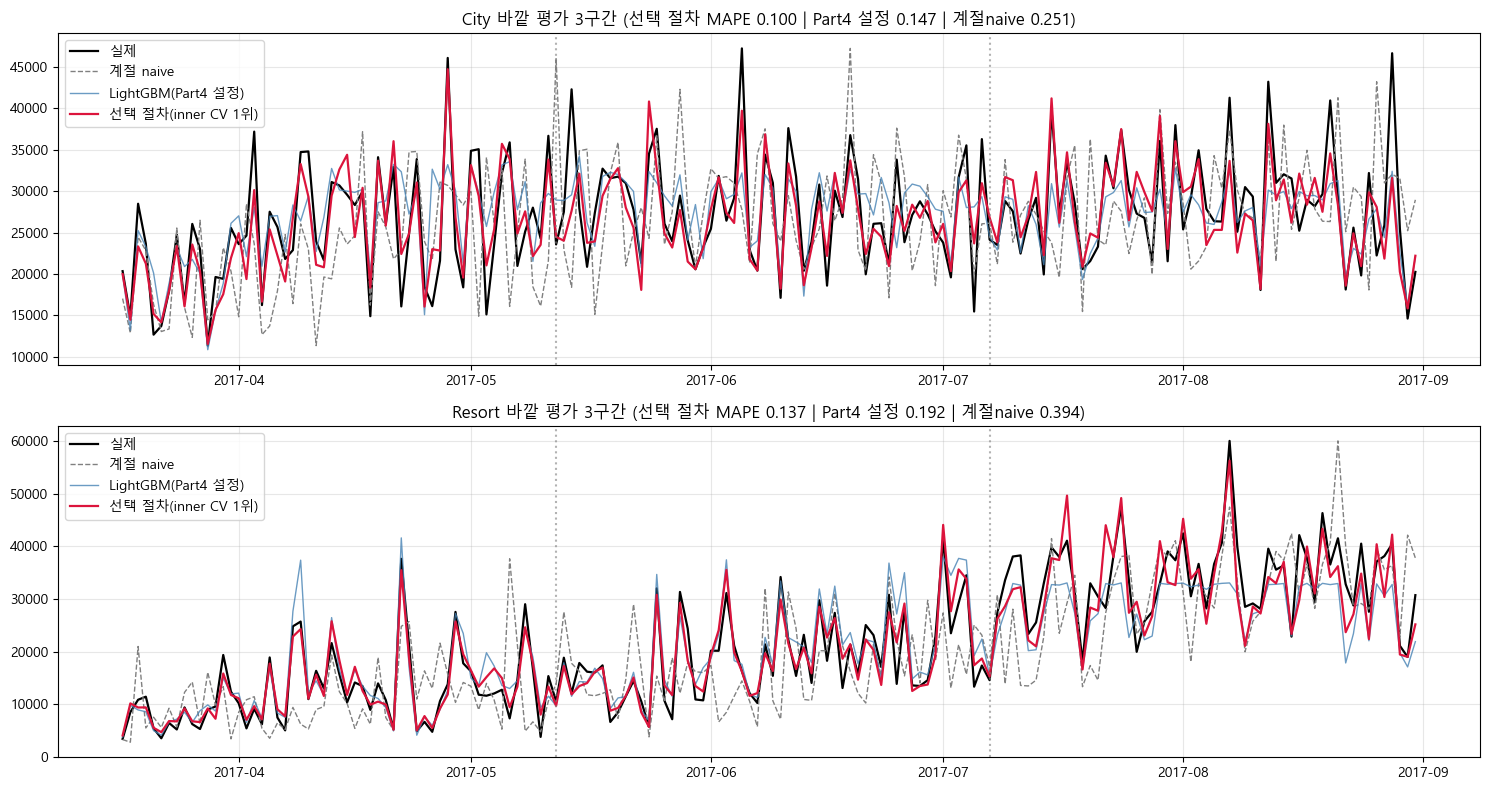

In [13]:
for hotel in HOTELS:
    ys, preds, dates, fold_id = outer[hotel]
    e = pd.DataFrame({'date': pd.to_datetime(dates), 'y': ys, 'pred': preds[SEL]}); e['err'] = e['pred'] - e['y']; e['abs'] = e['err'].abs()
    e['month'] = e['date'].dt.month; e['dow'] = e['date'].dt.dayofweek
    q1, q2 = e.y.quantile(1 / 3), e.y.quantile(2 / 3); w = lambda g: g['abs'].sum() / g['y'].sum()
    print(f"\n===== {hotel} [{SEL}] =====")
    print("월별 WAPE:", (e.groupby('month')['abs'].sum() / e.groupby('month')['y'].sum()).round(3).to_dict())
    print("요일별 WAPE(0=월):", (e.groupby('dow')['abs'].sum() / e.groupby('dow')['y'].sum()).round(3).to_dict())
    print(f"수요 규모별 WAPE: 하위1/3 {w(e[e.y <= q1]):.3f} | 중위 {w(e[(e.y > q1) & (e.y <= q2)]):.3f} | 상위1/3 {w(e[e.y > q2]):.3f}")
    print("오차가 큰 날 상위 5:"); print(e.assign(ape=e['abs'] / e['y']).nlargest(5, 'abs')[['date', 'y', 'pred', 'err', 'ape']].round(2).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, hotel in zip(axes, HOTELS):
    ys, preds, dates, fold_id = outer[hotel]; x = pd.to_datetime(dates)
    ax.plot(x, ys, color='black', linewidth=1.6, label='실제')
    ax.plot(x, preds['계절naive(lag_14)'], color='gray', linestyle='--', linewidth=1, label='계절 naive')
    ax.plot(x, preds['LightGBM(Part4 설정)'], color='steelblue', alpha=0.8, linewidth=1, label='LightGBM(Part4 설정)')
    ax.plot(x, preds[SEL], color='crimson', linewidth=1.6, label='선택 절차(inner CV 1위)')
    for k in (1, 2): ax.axvline(x[fold_id == k][0], color='gray', linestyle=':', alpha=0.6)
    ax.set_title(f"{hotel} 바깥 평가 3구간 (선택 절차 MAPE {mape(ys, preds[SEL]):.3f} | Part4 설정 {mape(ys, preds['LightGBM(Part4 설정)']):.3f} | 계절naive {mape(ys, preds['계절naive(lag_14)']):.3f})")
    ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('revenue_nested.png', dpi=120, bbox_inches='tight'); plt.show()

## 12. 배포용 최종 설정 (outer 3: 전체 DEV로 선택)

평가 없이 전체 데이터에서 같은 절차로 선택한 설정이다. 위 바깥 구간들에서 이 절차의 성능을 검증했다.

In [14]:
for hotel in HOTELS:
    r = R[(3, hotel)]
    print(f"\n===== {hotel} 배포용 설정 (DEV {r['ts']}일 전체) =====")
    print("채택된 EDA 그룹:", r['groups'] or '(없음)', f"| 피처 수 {r['n_feats']}")
    print(f"LightGBM 타깃방식 {r['lgb'][2]} | 파라미터 {r['lgb'][1]}")
    im = pd.Series(r['inner_mape']).sort_values()
    print("inner CV MAPE 순위:", {k: round(v, 4) for k, v in im.items()})
    print("최종 모델(inner CV 1위):", r['final'])


===== City 배포용 설정 (DEV 658일 전체) =====
채택된 EDA 그룹: ['cancel', 'calendar'] | 피처 수 31
LightGBM 타깃방식 raw | 파라미터 {'num_leaves': 7, 'min_child_samples': 20, 'learning_rate': 0.05, 'feature_fraction': 0.6, 'lambda_l2': 0.0}
inner CV MAPE 순위: {'SARIMAX+OTB': 0.106, 'RandomForest': 0.1229, 'HistGB': 0.1269, '블렌드(LGBM+Ridge)': 0.1271, 'LightGBM(튜닝)': 0.1291, 'Ridge': 0.1327, 'LightGBM(Part4 설정)': 0.1755, 'ETS(주간계절)': 0.2332, '계절naive(lag_14)': 0.2873}
최종 모델(inner CV 1위): SARIMAX+OTB

===== Resort 배포용 설정 (DEV 658일 전체) =====
채택된 EDA 그룹: ['cancel', 'segment', 'cancel_lag'] | 피처 수 33
LightGBM 타깃방식 raw | 파라미터 {'num_leaves': 31, 'learning_rate': 0.05, 'feature_fraction': 0.8, 'min_child_samples': 20, 'lambda_l2': 0.0}
inner CV MAPE 순위: {'블렌드(LGBM+Ridge)': 0.1414, 'Ridge': 0.1434, 'SARIMAX+OTB': 0.1482, 'RandomForest': 0.1497, 'LightGBM(튜닝)': 0.1498, 'HistGB': 0.1499, 'LightGBM(Part4 설정)': 0.1991, 'ETS(주간계절)': 0.4142, '계절naive(lag_14)': 0.4641}
최종 모델(inner CV 1위): 블렌드(LGBM+Ridge)


## 부록. SARIMAX 외생변수 ablation: 취소 보정 지표의 기여 분리

최종 모델이 SARIMAX인 호텔에서 EDA(취소 예측)의 기여는 외생변수에 쓰인 **취소 보정 지표** 하나다. 이를 분리해서 확인한다.
- `otb_rev_7`만: 이미 잡힌 예약의 예상 매출 (취소 여부를 모르는 시점의 단순 합)
- `exp_rev_7`만: 취소 확률로 보정한 기대 값
- `otb_rev_7 + exp_rev_7` (현재): 둘 다

세 설정은 모두 같은 SARIMAX(1,0,1)x(1,0,0,7), 같은 바깥 평가 구간 3개(168일)에서 비교한다. 고정된 설정을 비교하는 것이라 선택 과정은 없다. 7일 블록 부트스트랩으로 현재 설정과의 차이의 95% 신뢰구간을 계산한다.

In [15]:
EXOG_VARIANTS = {'otb_rev_7만': ['otb_rev_7'], 'exp_rev_7만': ['exp_rev_7'], 'otb_rev_7 + exp_rev_7': ['otb_rev_7', 'exp_rev_7']}
abl_rows, abl_pred, abl_y = [], {}, {}
for hotel in HOTELS:
    d = frames[hotel]; ys_all = []; preds = {v: [] for v in EXOG_VARIANTS}
    for k in range(3):
        ts = OUTER_TS[k]; ofold = [(ts - VAL_LEN, ts, min(ts + TEST_LEN, N))]
        for name, cols in EXOG_VARIANTS.items():
            yo, po = run_classical(d, classical_fp('sarimax', cols), ofold); preds[name].append(po)
        ys_all.append(yo)
    y_cat = np.concatenate(ys_all); abl_y[hotel] = y_cat
    for name in EXOG_VARIANTS:
        pr = np.concatenate(preds[name]); abl_pred[(hotel, name)] = pr; mm = metrics(y_cat, pr)
        abl_rows.append({'hotel': hotel, '외생변수': name, '168일 MAPE': mm['MAPE'], 'WAPE': mm['WAPE'], '편향': mm['편향']})
abl_tbl = pd.DataFrame(abl_rows)
print(abl_tbl.round(4).to_string(index=False))

cur = list(EXOG_VARIANTS)[-1]
for hotel in HOTELS:
    y_cat = abl_y[hotel]; ape_cur = np.abs(y_cat - abl_pred[(hotel, cur)]) / np.maximum(y_cat, 1)
    for name in list(EXOG_VARIANTS)[:-1]:
        diff = ape_cur - np.abs(y_cat - abl_pred[(hotel, name)]) / np.maximum(y_cat, 1); lo, hi = block_ci(diff)
        print(f"{hotel}: [현재] vs [{name}]  MAPE 차이 {diff.mean():+.4f}  95%CI [{lo:+.4f}, {hi:+.4f}]  -> {'현재가 유의하게 좋음' if hi < 0 else ('현재가 유의하게 나쁨' if lo > 0 else '불확실')}")


 hotel                  외생변수  168일 MAPE   WAPE        편향
  City            otb_rev_7만     0.1575 0.1540 -773.9970
  City            exp_rev_7만     0.0979 0.0978 -722.7358
  City otb_rev_7 + exp_rev_7     0.0999 0.0988 -564.6736
Resort            otb_rev_7만     0.1708 0.1446  396.9390
Resort            exp_rev_7만     0.1314 0.1168 -619.9432
Resort otb_rev_7 + exp_rev_7     0.1369 0.1196 -424.4806
City: [현재] vs [otb_rev_7만]  MAPE 차이 -0.0576  95%CI [-0.0834, -0.0350]  -> 현재가 유의하게 좋음
City: [현재] vs [exp_rev_7만]  MAPE 차이 +0.0020  95%CI [-0.0028, +0.0081]  -> 불확실
Resort: [현재] vs [otb_rev_7만]  MAPE 차이 -0.0339  95%CI [-0.0478, -0.0217]  -> 현재가 유의하게 좋음


Resort: [현재] vs [exp_rev_7만]  MAPE 차이 +0.0055  95%CI [+0.0002, +0.0119]  -> 현재가 유의하게 나쁨
